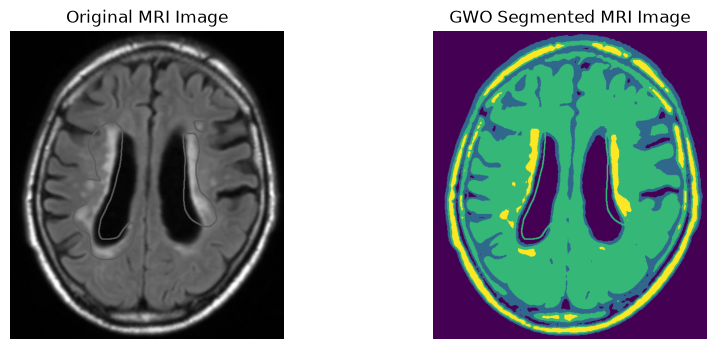

Optimized thresholds: [0.10830402 0.29112925 0.54654186]


In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load MRI image
image = cv2.imread("mri.jpg", 0)

if image is None:
    raise ValueError("MRI image not found")

# Normalize image
image = image.astype(np.float64) / 255.0

# GWO parameters
wolves = 10
iterations = 30
dimensions = 3

# Initialize wolf positions (segmentation thresholds)
positions = np.random.rand(wolves, dimensions)
positions.sort(axis=1)

# Fitness function using within-cluster variance
def fitness(thresholds):
    t1, t2, t3 = thresholds

    groups = [
        image[image <= t1],
        image[(image > t1) & (image <= t2)],
        image[(image > t2) & (image <= t3)],
        image[image > t3]
    ]

    total = 0

    for group in groups:
        if len(group) > 0:
            total += np.sum((group - np.mean(group)) ** 2)

    return total

# GWO optimization
for iteration in range(iterations):

    scores = np.array([fitness(p) for p in positions])

    order = np.argsort(scores)

    alpha = positions[order[0]].copy()
    beta = positions[order[1]].copy()
    delta = positions[order[2]].copy()

    a = 2 - 2 * iteration / iterations

    for i in range(wolves):

        for leader in [alpha, beta, delta]:

            r1 = np.random.rand(dimensions)
            r2 = np.random.rand(dimensions)

            A = 2 * a * r1 - a
            C = 2 * r2

            D = abs(C * leader - positions[i])
            X = leader - A * D

            if leader is alpha:
                X1 = X.copy()
            elif leader is beta:
                X2 = X.copy()
            else:
                X3 = X.copy()

        positions[i] = (X1 + X2 + X3) / 3
        positions[i] = np.clip(positions[i], 0, 1)
        positions[i].sort()

# Get optimized thresholds
scores = np.array([fitness(p) for p in positions])
best = positions[np.argmin(scores)]

# Segment MRI image
segmented = np.digitize(image, best)

# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original MRI Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap="viridis")
plt.title("GWO Segmented MRI Image")
plt.axis("off")

plt.show()

print("Optimized thresholds:", best)